In [ ]:
from tensorflow import keras
from keras import Sequential
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from keras.layers import Dense, LeakyReLU, Conv2D, Flatten, MaxPooling2D, GlobalAveragePooling2D, Dropout, BatchNormalization
from keras.callbacks import EarlyStopping

In [ ]:
data_dir = "C:\\Users\\Walter\\Desktop\\PetImages"
input_size = (200, 200)
val_frac = 0.30
batch_size = 32

data_augmentor = ImageDataGenerator(
    rescale=1./255,
    validation_split=val_frac
)

train_generator = data_augmentor.flow_from_directory(
    data_dir,
    target_size=input_size,
    batch_size=batch_size,
    shuffle=True,
    subset='training',
    class_mode='binary'
)

val_generator = data_augmentor.flow_from_directory(
    data_dir,
    target_size=input_size,
    batch_size=batch_size,
    shuffle=False,
    subset='validation',
    class_mode='binary'
)

In [ ]:
model = Sequential()

model.add(Conv2D(32, kernel_size=(3,3), padding='same', activation='relu', input_shape=(200,200,3)))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2), strides=2, padding='same'))

model.add(Conv2D(64, kernel_size=(3,3), padding='same', activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2), strides=2, padding='same'))

model.add(Conv2D(128, kernel_size=(3,3), padding='same', activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2), strides=2, padding='same'))

model.add(Conv2D(256, kernel_size=(3,3), padding='same', activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2), strides=2, padding='same'))

model.add(Conv2D(512, kernel_size=(3,3), padding='same', activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2), strides=2, padding='same'))


model.add(GlobalAveragePooling2D())

model.add(Dense(128))
model.add(LeakyReLU(alpha=0.2))
model.add(Dropout(0.3))
model.add(Dense(64))
model.add(LeakyReLU(alpha=0.2))
model.add(Dropout(0.2))
model.add(Dense(1, activation='sigmoid'))

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)





In [66]:


early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)


history = model.fit(train_generator, epochs=50, validation_data=val_generator, callbacks=[early_stop])

Epoch 1/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 1382s 2s/step - accuracy: 0.6488 - loss: 0.6371 - val_accuracy: 0.5044 - val_loss: 1.6219
Epoch 2/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 1440s 2s/step - accuracy: 0.7508 - loss: 0.5162 - val_accuracy: 0.7258 - val_loss: 0.5480
Epoch 3/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 1479s 2s/step - accuracy: 0.8486 - loss: 0.3538 - val_accuracy: 0.6713 - val_loss: 0.7079
Epoch 4/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 1514s 2s/step - accuracy: 0.9053 - loss: 0.2303 - val_accuracy: 0.8587 - val_loss: 0.2998
Epoch 5/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 1476s 2s/step - accuracy: 0.9317 - loss: 0.1703 - val_accuracy: 0.8187 - val_loss: 0.3438
Epoch 6/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 75614s 108s/step - accuracy: 0.9469 - loss: 0.1331 - val_accuracy: 0.9271 - val_loss: 0.1901
Epoch 7/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 1480s 2s/step - accuracy: 0.9591 - loss: 0.1070 - val_accuracy: 0.9007 - val_loss: 0.2571
Epoch 8/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 1400s 2s/step - accuracy: 0.9675 - loss: 0.0852

  Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.67.0-cp314-cp314-win_amd64.whl.metadata (139 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl (9.5 MB)
Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl (240 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.67.0-cp314-cp314-win_amd64.whl (2.5 MB)
Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl (72 kB)
Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)

   ---------------------------------------- 0/6 [pyparsing]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- --

Matplotlib is building the font cache; this may take a moment.


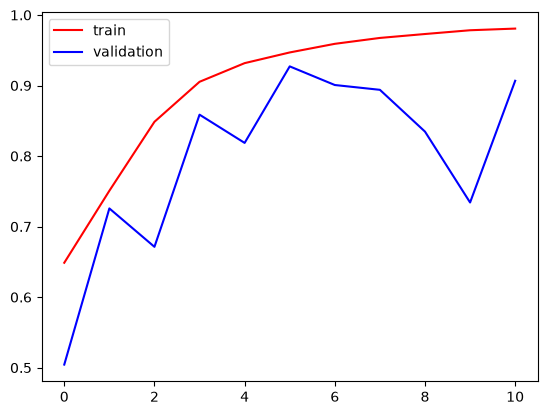

In [70]:
%pip install matplotlib
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], color='red',label='train')
plt.plot(history.history['val_accuracy'],color='blue',label='validation')
plt.legend()
plt.show()

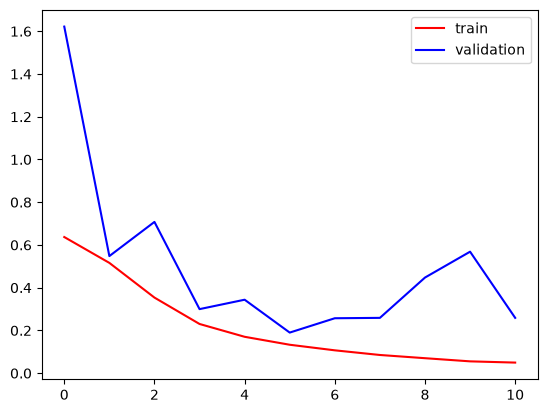

In [71]:
plt.plot(history.history['loss'], color='red',label='train')
plt.plot(history.history['val_loss'],color='blue',label='validation')
plt.legend()
plt.show()
